<a href="https://colab.research.google.com/github/chetankodigantiML/ECGR4105-F26/blob/main/HW5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [29]:
import torch
import matplotlib.pyplot as plt
from google.colab import drive
import numpy as np
import torch.optim as optim
import pandas as pd
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Problem 1 - Temperature

In [32]:
def model(t_c, w, type):
  if type == 'linear':
    return (w[0]*t_c + w[1])
  elif type == 'multilinear':
    return (torch.matmul(t_c, w[1:]) + w[0])
  elif type == 'nonlinear':
    return (w[0]**2*t_c + w[1]*t_c + w[2])

def loss_fn(t_c, t_p):
  return ((t_c - t_p)**2).mean()

In [33]:
def reg_training(t_c, t_u, weights, a, epochs, type):
  w = torch.tensor(weights, requires_grad=True)
  optimizer = optim.SGD([w], lr=a)
  losses = np.zeros(int(epochs/500)+1)
  for i in range(1, epochs+1):
    t_calc = model(t_c, w, type)
    loss = loss_fn(t_calc, t_u)
    if i == 1:
      losses[0] = float(loss_fn(model(t_c, w, type), t_u))
      print(f'Epoch: 0, Loss: {float(loss)}')


    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if i % 500 == 0:
      losses[int(i/500)] = float(loss)
      print(f'Epoch: {i}, Loss: {float(loss)}')

  return w, losses


In [35]:
t_c = torch.tensor([0.5, 14.0, 15.0, 28.0, 11.0, 8.0, 3.0, -4.0, 6.0, 13.0, 21.0])
t_u = torch.tensor([35.7, 55.9, 58.2, 81.9, 56.3, 48.9, 33.9, 21.8, 48.4, 60.4, 68.4])
w = [1.0, 1.0, 0.0]
w_1, losses_1 = reg_training(t_c, t_u, w, 0.1, 5000, 'nonlinear')
w_2, losses_2 = reg_training(t_c, t_u, w, 0.01, 5000, 'nonlinear')
w_3, losses_3 = reg_training(t_c, t_u, w, 0.001, 5000, 'nonlinear')
w_4, losses_4 = reg_training(t_c, t_u, w, 0.0001, 5000, 'nonlinear')

Epoch: 0, Loss: 961.7437133789062
Epoch: 500, Loss: nan
Epoch: 1000, Loss: nan
Epoch: 1500, Loss: nan
Epoch: 2000, Loss: nan
Epoch: 2500, Loss: nan
Epoch: 3000, Loss: nan
Epoch: 3500, Loss: nan
Epoch: 4000, Loss: nan
Epoch: 4500, Loss: nan
Epoch: 5000, Loss: nan
Epoch: 0, Loss: 961.7437133789062
Epoch: 500, Loss: nan
Epoch: 1000, Loss: nan
Epoch: 1500, Loss: nan
Epoch: 2000, Loss: nan
Epoch: 2500, Loss: nan
Epoch: 3000, Loss: nan
Epoch: 3500, Loss: nan
Epoch: 4000, Loss: nan
Epoch: 4500, Loss: nan
Epoch: 5000, Loss: nan
Epoch: 0, Loss: 961.7437133789062
Epoch: 500, Loss: nan
Epoch: 1000, Loss: nan
Epoch: 1500, Loss: nan
Epoch: 2000, Loss: nan
Epoch: 2500, Loss: nan
Epoch: 3000, Loss: nan
Epoch: 3500, Loss: nan
Epoch: 4000, Loss: nan
Epoch: 4500, Loss: nan
Epoch: 5000, Loss: nan
Epoch: 0, Loss: 961.7437133789062
Epoch: 500, Loss: 421.90966796875
Epoch: 1000, Loss: 389.3466796875
Epoch: 1500, Loss: 359.356689453125
Epoch: 2000, Loss: 331.7363586425781
Epoch: 2500, Loss: 306.2986145019531

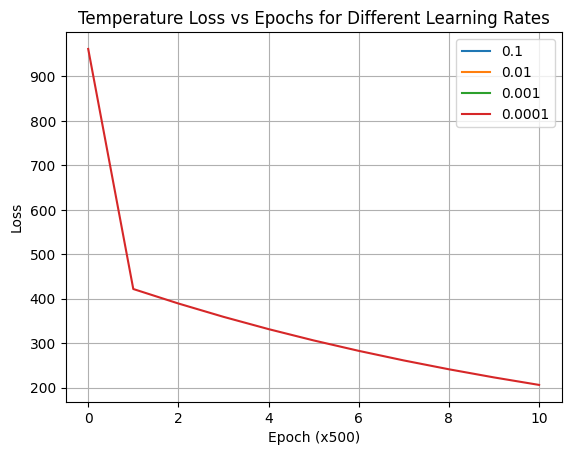

In [36]:
plt.plot(losses_1, label='0.1')
plt.plot(losses_2, label='0.01')
plt.plot(losses_3, label='0.001')
plt.plot(losses_4, label='0.0001')
plt.grid()
plt.title('Temperature Loss vs Epochs for Different Learning Rates')
plt.xlabel('Epoch (x500)')
plt.ylabel('Loss')
plt.legend()
plt.show()

# Problem 2

In [37]:
data = pd.read_csv('/content/drive/My Drive/Fall26/ECGR4105/HW5/Housing.csv')
data.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [38]:
colms = ['area', 'bedrooms', 'bathrooms', 'stories', 'parking']
scaler = MinMaxScaler()
data[colms] = scaler.fit_transform(data[colms])

train, test = train_test_split(data, test_size=0.2, random_state=42)

train_x, train_y = torch.tensor(train[colms].values), torch.tensor(train['price'].values)
test_x, test_y = torch.tensor(test[colms].values), torch.tensor(test['price'].values)

In [48]:
w = torch.ones(len(colms) + 1, dtype=torch.float32)
w[0] = 0.0

house_w1, house_losses1 = reg_training(train_x.float(), train_y.float(), w, 0.1, 5000, 'multilinear')
house_w2, house_losses2 = reg_training(train_x.float(), train_y.float(), w, 0.01, 5000, 'multilinear')
house_w3, house_losses3 = reg_training(train_x.float(), train_y.float(), w, 0.001, 5000, 'multilinear')
house_w4, house_losses4 = reg_training(train_x.float(), train_y.float(), w, 0.0001, 5000, 'multilinear')

/tmp/ipykernel_503/2710971548.py:2: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  w = torch.tensor(weights, requires_grad=True)


Epoch: 0, Loss: 25234780454912.0
Epoch: 500, Loss: 1358686322688.0
Epoch: 1000, Loss: 1350310035456.0
Epoch: 1500, Loss: 1350024036352.0
Epoch: 2000, Loss: 1350009225216.0
Epoch: 2500, Loss: 1350008176640.0
Epoch: 3000, Loss: 1350008176640.0
Epoch: 3500, Loss: 1350008045568.0
Epoch: 4000, Loss: 1350008045568.0
Epoch: 4500, Loss: 1350008176640.0
Epoch: 5000, Loss: 1350008176640.0
Epoch: 0, Loss: 25234780454912.0
Epoch: 500, Loss: 1699868966912.0
Epoch: 1000, Loss: 1556255473664.0
Epoch: 1500, Loss: 1481826238464.0
Epoch: 2000, Loss: 1436944433152.0
Epoch: 2500, Loss: 1408152895488.0
Epoch: 3000, Loss: 1389229244416.0
Epoch: 3500, Loss: 1376647512064.0
Epoch: 4000, Loss: 1368219844608.0
Epoch: 4500, Loss: 1362538266624.0
Epoch: 5000, Loss: 1358683963392.0
Epoch: 0, Loss: 25234780454912.0
Epoch: 500, Loss: 3540330479616.0
Epoch: 1000, Loss: 2057299165184.0
Epoch: 1500, Loss: 1917634215936.0
Epoch: 2000, Loss: 1870882930688.0
Epoch: 2500, Loss: 1834175430656.0
Epoch: 3000, Loss: 1801548201

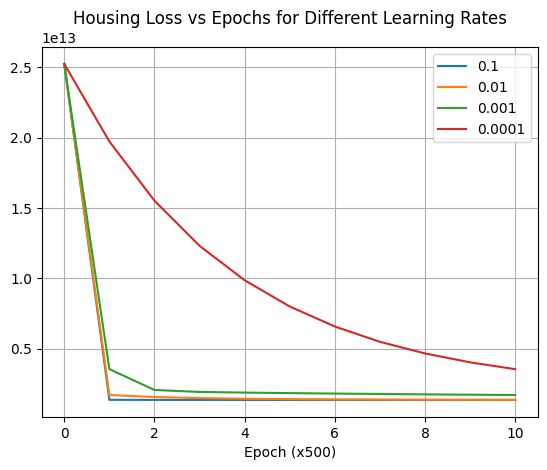

In [40]:
plt.plot(house_losses1, label='0.1')
plt.plot(house_losses2, label='0.01')
plt.plot(house_losses3, label='0.001')
plt.plot(house_losses4, label='0.0001')
plt.grid()
plt.title('Housing Loss vs Epochs for Different Learning Rates')
plt.xlabel('Epoch (x500)')
plt.legend()
plt.show()

# Problem 3

In [41]:
def binary_map(x):
  return x.map({'yes': 1, 'no': 0})

def furnish_map(x):
  return x.map({'furnished': 1, 'semi-furnished': 0.5, 'unfurnished': 0})

In [42]:
data[['mainroad']] = data[['mainroad']].apply(binary_map)
data[['guestroom']] = data[['guestroom']].apply(binary_map)
data[['basement']] = data[['basement']].apply(binary_map)
data[['hotwaterheating']] = data[['hotwaterheating']].apply(binary_map)
data[['airconditioning']] = data[['airconditioning']].apply(binary_map)
data[['prefarea']] = data[['prefarea']].apply(binary_map)
data[['furnishingstatus']] = data[['furnishingstatus']].apply(furnish_map)

data.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,0.396564,0.6,0.333333,0.666667,1,0,0,0,1,0.666667,1,1.0
1,12250000,0.502405,0.6,1.000000,1.000000,1,0,0,0,1,1.000000,0,1.0
2,12250000,0.571134,0.4,0.333333,0.333333,1,0,1,0,0,0.666667,1,0.5
3,12215000,0.402062,0.6,0.333333,0.333333,1,0,1,0,1,1.000000,1,1.0
4,11410000,0.396564,0.6,0.000000,0.333333,1,1,1,0,1,0.666667,0,1.0


In [43]:
train_3, test_3 = train_test_split(data, test_size=0.2, random_state=42)

train_3x, train_3y = torch.tensor(train_3.drop(columns='price').values).float(), torch.tensor(train_3['price'].values).float()
test_3x, test_3y = torch.tensor(test_3.drop(columns='price').values).float(), torch.tensor(test_3['price'].values).float()


In [47]:
w3 = torch.ones(len(train_3x[0])+1, dtype=torch.float32)
w3[0] = 0.0

house3_w1, house3_losses1 = reg_training(train_3x, train_3y, w3, 0.1, 5000, 'multilinear')
house3_w2, house3_losses2 = reg_training(train_3x, train_3y, w3, 0.01, 5000, 'multilinear')
house3_w3, house3_losses3 = reg_training(train_3x, train_3y, w3, 0.001, 5000, 'multilinear')
house3_w4, house3_losses4 = reg_training(train_3x, train_3y, w3, 0.0001, 5000, 'multilinear')

/tmp/ipykernel_503/2710971548.py:2: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  w = torch.tensor(weights, requires_grad=True)


Epoch: 0, Loss: 25234753191936.0
Epoch: 500, Loss: 978110906368.0
Epoch: 1000, Loss: 970307076096.0
Epoch: 1500, Loss: 969929588736.0
Epoch: 2000, Loss: 969904685056.0
Epoch: 2500, Loss: 969902915584.0
Epoch: 3000, Loss: 969902850048.0
Epoch: 3500, Loss: 969902850048.0
Epoch: 4000, Loss: 969902784512.0
Epoch: 4500, Loss: 969902850048.0
Epoch: 5000, Loss: 969902784512.0
Epoch: 0, Loss: 25234753191936.0
Epoch: 500, Loss: 1258933977088.0
Epoch: 1000, Loss: 1131679580160.0
Epoch: 1500, Loss: 1072282075136.0
Epoch: 2000, Loss: 1038231994368.0
Epoch: 2500, Loss: 1016648040448.0
Epoch: 3000, Loss: 1002329079808.0
Epoch: 3500, Loss: 992621363200.0
Epoch: 4000, Loss: 985955631104.0
Epoch: 4500, Loss: 981334949888.0
Epoch: 5000, Loss: 978104811520.0
Epoch: 0, Loss: 25234753191936.0
Epoch: 500, Loss: 1730377940992.0
Epoch: 1000, Loss: 1556180893696.0
Epoch: 1500, Loss: 1492141604864.0
Epoch: 2000, Loss: 1440473546752.0
Epoch: 2500, Loss: 1397637644288.0
Epoch: 3000, Loss: 1361457709056.0
Epoch: 3

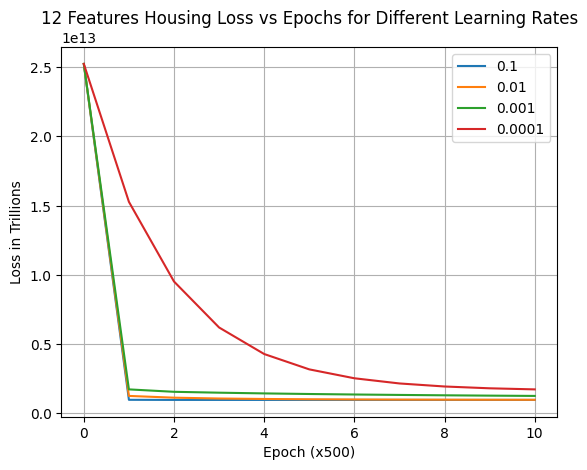

In [14]:
plt.plot(house3_losses1, label='0.1')
plt.plot(house3_losses2, label='0.01')
plt.plot(house3_losses3, label='0.001')
plt.plot(house3_losses4, label='0.0001')
plt.grid()
plt.title('12 Features Housing Loss vs Epochs for Different Learning Rates')
plt.xlabel('Epoch (x500)')
plt.ylabel('Loss in Trillions')
plt.legend()
plt.show()